# 02 · Analysis

Answers the six analysis questions with Spark's DataFrame API, using the Parquet tables
written by `01_data_preparation.ipynb`.

| # | Question | Tables |
|---|---|---|
| 1 | ¿Cómo evolucionó el dengue entre 2000 y 2025 y qué años fueron epidémicos? | `dengue_cases` |
| 2 | ¿Qué distritos tuvieron la mayor incidencia (casos por 100,000 habitantes) en 2022–2025? | `dengue_cases`, `population` |
| 3 | ¿Qué grupos de edad y qué sexo tienen la mayor incidencia? | `dengue_cases`, `population` |
| 4 | ¿La proporción de casos con signos de alarma o graves se relaciona con la cobertura de establecimientos de salud? | `dengue_cases`, `health_facilities`, `population` |
| 5 | ¿Los distritos en emergencia hídrica tuvieron mayor incidencia? ¿Influye la continuidad del servicio de agua? | `dengue_cases`, `population`, `water_emergencies` |
| 6 | ¿Cuántas semanas después de la lluvia aumentan los casos, y es distinto en la costa y en la selva? | `dengue_cases`, `weather_daily` |

Population is only available for 2022–2025, so every rate uses those years. Spark does all the
processing; matplotlib only draws results that Spark already aggregated (a few dozen rows). Each chart is
also saved to `docs/figures/` for the report.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pyspark.sql import SparkSession, Window, functions as F

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "catalog.yaml").exists())
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder
         .master("local[*]")
         .appName("dengue-analysis")
         .config("spark.sql.session.timeZone", "America/Lima")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

cases, population, emergencies, facilities, weather = (
    spark.read.parquet(str(PROCESSED / name))
    for name in ["dengue_cases", "population", "water_emergencies", "health_facilities", "weather_daily"])

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/02 11:38:49 WARN Utils: Your hostname, Raymonds-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 192.168.18.58 instead (on interface en0)
26/11/02 11:38:49 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/02 11:38:50 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
# Chart style (reference palette): light surface, hairline grid on the value axis, muted axes.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

## Q1 · ¿Cómo evolucionó el dengue entre 2000 y 2025 y qué años fueron epidémicos?

Un año se considera **epidémico** cuando tiene más del doble del promedio de los cinco años anteriores. Esa
línea base es una ventana con un marco (`rowsBetween(-5, -1)`); `lag` da la variación respecto al año anterior.
La ventana no tiene partición, así que Spark mueve las filas a una sola partición: no es un problema aquí,
porque opera sobre 26 filas ya agregadas.

In [3]:
yearly = (cases.groupBy("year")
          .agg(F.count("*").alias("cases"),
               F.sum((F.col("severity") != "without_warning_signs").cast("int")).alias("warning_or_severe"),
               F.round(F.avg(F.col("is_confirmed").cast("int")) * 100, 1).alias("pct_confirmed")))

by_year = Window.orderBy("year")
yearly = (yearly
          .withColumn("pct_change", F.round((F.col("cases") / F.lag("cases").over(by_year) - 1) * 100, 1))
          .withColumn("baseline_5y", F.round(F.avg("cases").over(by_year.rowsBetween(-5, -1))))
          .withColumn("epidemic", F.coalesce(F.col("cases") > 2 * F.col("baseline_5y"), F.lit(False)))
          .orderBy("year"))
yearly.show(30)

+----+------+-----------------+-------------+----------+-----------+--------+
|year| cases|warning_or_severe|pct_confirmed|pct_change|baseline_5y|epidemic|
+----+------+-----------------+-------------+----------+-----------+--------+
|2000|  5557|                0|         16.1|      NULL|       NULL|   false|
|2001| 23526|              250|          6.1|     323.4|     5557.0|    true|
|2002|  8086|               15|         25.7|     -65.6|    14542.0|   false|
|2003|  3349|               15|         15.2|     -58.6|    12390.0|   false|
|2004|  9547|               34|         17.3|     185.1|    10130.0|   false|
|2005|  5640|               15|         43.4|     -40.9|    10013.0|   false|
|2006|  4022|                4|         30.3|     -28.7|    10030.0|   false|
|2007|  6344|               35|         43.6|      57.7|     6129.0|   false|
|2008| 12824|               35|         52.7|     102.1|     5780.0|    true|
|2009| 13407|               11|         99.9|       4.5|     767

In [4]:
epidemic_years = [row.year for row in yearly.filter(F.col("epidemic")).select("year").collect()]
by_epidemic_year = Window.partitionBy("year")

top_departments = (cases.filter(F.col("year").isin(epidemic_years))
                   .groupBy("year", "department").agg(F.count("*").alias("cases"))
                   .withColumn("pct_of_year", F.round(F.col("cases") / F.sum("cases").over(by_epidemic_year) * 100, 1))
                   .withColumn("rank", F.row_number().over(by_epidemic_year.orderBy(F.desc("cases"))))
                   .filter(F.col("rank") <= 3)
                   .orderBy("year", "rank"))
print("Epidemic years:", epidemic_years)
top_departments.show(30)

Epidemic years: [2001, 2008, 2011, 2017, 2023, 2024]


+----+-------------+-----+-----------+----+
|year|   department|cases|pct_of_year|rank|
+----+-------------+-----+-----------+----+
|2001|        PIURA|11713|       49.8|   1|
|2001|  LA LIBERTAD| 5718|       24.3|   2|
|2001|       TUMBES| 1803|        7.7|   3|
|2008|       LORETO| 7232|       56.4|   1|
|2008|        PIURA| 1702|       13.3|   2|
|2008|      UCAYALI|  931|        7.3|   3|
|2011|       LORETO|21245|       75.6|   1|
|2011|MADRE DE DIOS| 1956|        7.0|   2|
|2011|      UCAYALI| 1770|        6.3|   3|
|2017|        PIURA|44275|       64.8|   1|
|2017|  LA LIBERTAD| 5904|        8.6|   2|
|2017|          ICA| 4384|        6.4|   3|
|2023|        PIURA|79304|       30.9|   1|
|2023|   LAMBAYEQUE|31460|       12.3|   2|
|2023|         LIMA|30735|       12.0|   3|
|2024|         LIMA|87864|       32.4|   1|
|2024|  LA LIBERTAD|49931|       18.4|   2|
|2024|        PIURA|32246|       11.9|   3|
+----+-------------+-----+-----------+----+



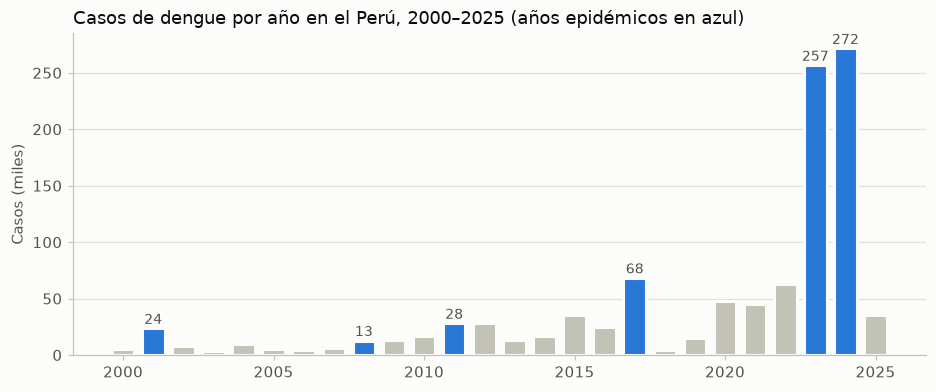

In [5]:
rows = yearly.select("year", "cases", "epidemic").collect()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar([r.year for r in rows], [r.cases / 1000 for r in rows], width=0.75,
       color=[BLUE if r.epidemic else AXIS for r in rows], edgecolor=SURFACE, linewidth=2)
for r in rows:
    if r.epidemic:
        ax.annotate(f"{r.cases / 1000:,.0f}", (r.year, r.cases / 1000), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_title("Casos de dengue por año en el Perú, 2000–2025 (años epidémicos en azul)")
ax.set_ylabel("Casos (miles)")
ax.set_xticks(range(2000, 2026, 5))
save(fig, "q1_cases_per_year")
plt.show()

**Respuesta.** El dengue avanza por brotes: años con pocos casos se alternan con epidemias, y las epidemias recientes son mucho más grandes. Pasó de unos 5 mil casos en 2000 a un récord de 272 mil en 2024.

Hubo **seis años epidémicos: 2001, 2008, 2011, 2017, 2023 y 2024**.

- 2001, 2017 y 2023: brotes en la **costa norte**, liderados por Piura.
- 2008 y 2011: brotes en la **Amazonía**, liderados por Loreto.
- 2023 y 2024 fueron las epidemias más grandes: juntas suman la mitad de todos los casos desde 2000. En 2025 los casos volvieron a bajar.

## Q2 · ¿Qué distritos tuvieron la mayor incidencia en 2022–2025?

Incidencia = casos por 100,000 habitantes, por distrito y año. Se excluyen los distritos con menos de 10,000
habitantes, porque ahí unos pocos casos producen tasas extremas e inestables.

**Tipo de join.** Los casos se agregan por distrito y año y luego se unen con la población mediante un
**LEFT JOIN**: la tabla de casos guía la consulta y ningún distrito con casos puede desaparecer. Antes de
confiar en él, un `left_anti` join confirma que todo distrito-año con casos tiene una fila de población.

El notebook 03 escribe esta misma consulta en Spark SQL y muestra que Catalyst convierte ambas versiones en
el mismo plan físico.

In [6]:
MIN_POPULATION = 10_000

district_cases = (cases.filter(F.col("year").between(2022, 2025))
                  .groupBy("year", "ubigeo").agg(F.count("*").alias("cases")))
district_population = (population
                       .groupBy("year", "ubigeo", "department", "province", "district")
                       .agg(F.sum("population").alias("population")))

missing = district_cases.join(district_population, ["year", "ubigeo"], "left_anti").count()
print("District-years with cases but no population:", missing)

top_districts = (district_cases
                    .join(district_population, ["year", "ubigeo"], "left")
                    .filter(F.col("population") >= MIN_POPULATION)
                    .withColumn("incidence_100k", F.round(F.col("cases") / F.col("population") * 100_000, 1))
                    .withColumn("rank", F.dense_rank().over(
                        Window.partitionBy("year").orderBy(F.desc(F.col("cases") / F.col("population")))))
                    .filter(F.col("rank") <= 5)
                    .select("year", "rank", "department", "province", "district", "cases", "population", "incidence_100k")
                    .orderBy("year", "rank"))
top_districts.show(20, truncate=False)

District-years with cases but no population: 0


+----+----+-----------+-----------------+--------------------+-----+----------+--------------+
|year|rank|department |province         |district            |cases|population|incidence_100k|
+----+----+-----------+-----------------+--------------------+-----+----------+--------------+
|2022|1   |ÁNCASH     |CASMA            |CASMA               |1927 |38179     |5047.3        |
|2022|2   |PIURA      |MORROPÓN         |MORROPÓN            |683  |14420     |4736.5        |
|2022|3   |AMAZONAS   |BAGUA            |BAGUA               |1342 |29254     |4587.4        |
|2022|4   |CUSCO      |LA CONVENCIÓN    |SANTA ANA           |1775 |41669     |4259.8        |
|2022|5   |JUNÍN      |CHANCHAMAYO      |SAN RAMÓN           |1110 |29710     |3736.1        |
|2023|1   |PIURA      |PAITA            |LA HUACA            |1890 |13958     |13540.6       |
|2023|2   |ÁNCASH     |SANTA            |NEPEÑA              |1428 |15854     |9007.2        |
|2023|3   |PIURA      |SULLANA          |MIGUEL CH

+----------+----------------+-----+--------------+--------------+
|department|district        |cases|avg_population|incidence_100k|
+----------+----------------+-----+--------------+--------------+
|PIURA     |LA HUACA        |2372 |14026.75      |4227.6        |
|ÁNCASH    |NEPEÑA          |2016 |15904.5       |3168.9        |
|ÁNCASH    |CASMA           |4911 |38887.0       |3157.2        |
|PIURA     |IGNACIO ESCUDERO|2699 |22637.0       |2980.7        |
|ÁNCASH    |HUARMEY         |3363 |29490.5       |2850.9        |
|PIURA     |SALITRAL        |1163 |10598.5       |2743.3        |
|TUMBES    |CORRALES        |2857 |26049.75      |2741.9        |
|CAJAMARCA |JAÉN            |12928|122594.0      |2636.3        |
|AMAZONAS  |BAGUA           |3069 |29917.25      |2564.6        |
|CUSCO     |SANTA ANA       |4299 |42013.0       |2558.1        |
|PIURA     |MORROPÓN        |1456 |14709.0       |2474.7        |
|PIURA     |CASTILLA        |17041|176109.25     |2419.1        |
|LORETO   

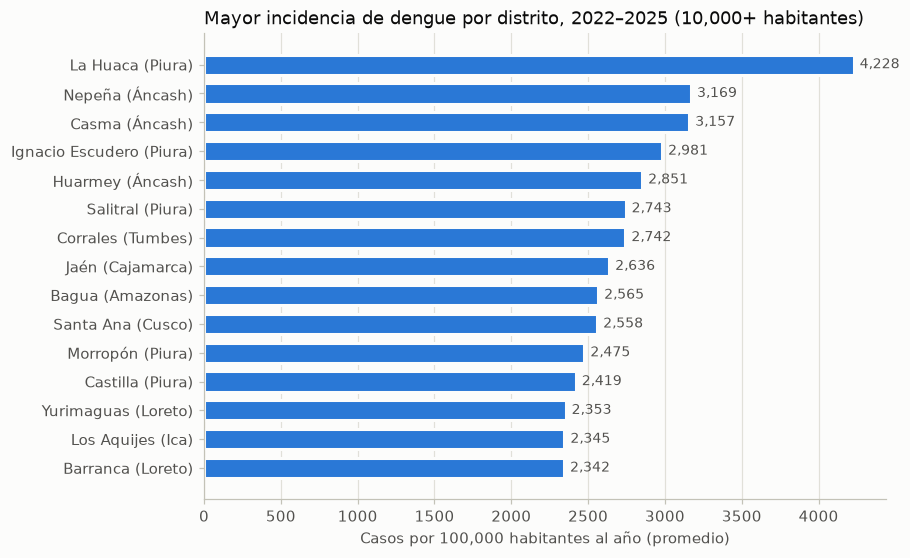

In [7]:
# Average yearly incidence over 2022-2025 (cases / person-years), for the chart
pooled = (district_cases.groupBy("ubigeo").agg(F.sum("cases").alias("cases"))
          .join(district_population.groupBy("ubigeo")
                .agg(F.max("department").alias("department"), F.max("district").alias("district"),
                     F.sum("population").alias("person_years"), F.avg("population").alias("avg_population")),
                "ubigeo", "left")
          .filter(F.col("avg_population") >= MIN_POPULATION)
          .withColumn("incidence_100k", F.round(F.col("cases") / F.col("person_years") * 100_000, 1))
          .orderBy(F.desc("incidence_100k")))
top15 = pooled.limit(15).collect()
pooled.select("department", "district", "cases", "avg_population", "incidence_100k").show(15, truncate=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
labels = [f"{r.district.title()} ({r.department.title()})" for r in reversed(top15)]
values = [r.incidence_100k for r in reversed(top15)]
ax.barh(labels, values, height=0.7, color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
for y, v in enumerate(values):
    ax.annotate(f"{v:,.0f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.set_title("Mayor incidencia de dengue por distrito, 2022–2025 (10,000+ habitantes)")
ax.set_xlabel("Casos por 100,000 habitantes al año (promedio)")
save(fig, "q2_top_districts")
plt.show()

**Respuesta.** El distrito con mayor incidencia fue **La Huaca (Paita, Piura)**: en promedio, 4,228 casos por 100,000 habitantes al año, es decir, unas 4 de cada 100 personas cada año.

La mayor incidencia se concentra en la **costa**: 10 de los 15 distritos con más incidencia están ahí, sobre todo en Piura y Áncash.

## Q3 · ¿Qué grupos de edad y qué sexo tienen la mayor incidencia?

Contar casos no basta: hay más adultos que niños, así que los adultos siempre tendrán más casos. La tasa
divide los casos entre las personas de cada grupo (sumadas en 2022–2025, es decir, personas-año).

**Tipo de join.** Ambos lados cubren la misma grilla completa (2 sexos × 5 etapas de vida), así que un
**INNER JOIN** no pierde nada y no requiere manejar nulos.

In [8]:
cases_by_group = (cases.filter(F.col("year").between(2022, 2025))
                  .groupBy("sex", "age_group").agg(F.count("*").alias("cases")))
population_by_group = population.groupBy("sex", "age_group").agg(F.sum("population").alias("person_years"))

rates = (cases_by_group.join(population_by_group, ["sex", "age_group"], "inner")
         .withColumn("pct_of_cases", F.round(F.col("cases") / F.sum("cases").over(Window.partitionBy()) * 100, 1))
         .withColumn("incidence_100k", F.round(F.col("cases") / F.col("person_years") * 100_000, 1))
         .orderBy("age_group", "sex"))
rates.show()

print("Incidence per 100,000 (rows: life stage, columns: sex)")
rates.groupBy("age_group").pivot("sex", ["F", "M"]).agg(F.first("incidence_100k")).orderBy("age_group").show()
(rates.groupBy("sex")
 .agg(F.round(F.sum("cases") / F.sum("person_years") * 100_000, 1).alias("incidence_100k"))
 .orderBy("sex").show())

+---+---------+------+------------+------------+--------------+
|sex|age_group| cases|person_years|pct_of_cases|incidence_100k|
+---+---------+------+------------+------------+--------------+
|  F|    00-11| 47707|    12802224|         7.6|         372.6|
|  M|    00-11| 51534|    13304133|         8.2|         387.4|
|  F|    12-17| 39375|     7134244|         6.3|         551.9|
|  M|    12-17| 44882|     7393723|         7.2|         607.0|
|  F|    18-29| 75334|    13294031|        12.0|         566.7|
|  M|    18-29| 61800|    13660719|         9.9|         452.4|
|  F|    30-59|141877|    27481464|        22.6|         516.3|
|  M|    30-59|101571|    27623393|        16.2|         367.7|
|  F|      60+| 35065|    10112381|         5.6|         346.8|
|  M|      60+| 28097|     9164910|         4.5|         306.6|
+---+---------+------+------------+------------+--------------+

Incidence per 100,000 (rows: life stage, columns: sex)


+---------+-----+-----+
|age_group|    F|    M|
+---------+-----+-----+
|    00-11|372.6|387.4|
|    12-17|551.9|607.0|
|    18-29|566.7|452.4|
|    30-59|516.3|367.7|
|      60+|346.8|306.6|
+---------+-----+-----+

+---+--------------+
|sex|incidence_100k|
+---+--------------+
|  F|         479.2|
|  M|         404.6|
+---+--------------+



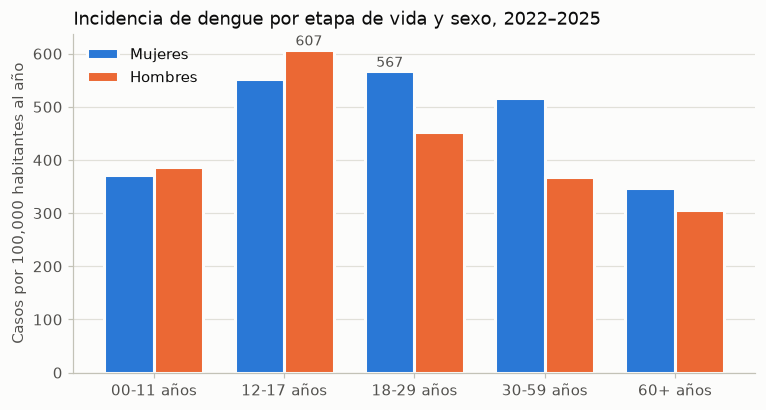

In [9]:
grid = {(r.age_group, r.sex): r.incidence_100k for r in rates.collect()}
groups = sorted({g for g, _ in grid})
width = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
for offset, (sex, label, color) in zip((-width / 2, width / 2), (("F", "Mujeres", BLUE), ("M", "Hombres", ORANGE))):
    values = [grid[(g, sex)] for g in groups]
    ax.bar([i + offset for i in range(len(groups))], values, width=width, color=color, label=label,
           edgecolor=SURFACE, linewidth=2)
    peak = max(range(len(groups)), key=lambda i: values[i])
    ax.annotate(f"{values[peak]:,.0f}", (peak + offset, values[peak]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_xticks(range(len(groups)), [f"{g} años" for g in groups])
ax.set_title("Incidencia de dengue por etapa de vida y sexo, 2022–2025")
ax.set_ylabel("Casos por 100,000 habitantes al año")
ax.legend(loc="upper left")
save(fig, "q3_age_sex")
plt.show()

**Respuesta.**

- **Edad:** la incidencia más alta está en los **adolescentes de 12 a 17 años**.
- **Sexo:** las **mujeres** tienen más incidencia que los hombres (479 vs 405 casos por 100,000 al año). La diferencia viene de las mujeres adultas (18 a 59 años); en niños y adolescentes los varones están ligeramente por encima.

Los adultos de 30 a 59 años son los que más casos suman, pero solo porque son el grupo más numeroso: su tasa no es la más alta.

## Q4 · ¿La proporción de casos con signos de alarma o graves se relaciona con la cobertura de establecimientos de salud?

Para cada distrito con al menos 30 casos en 2022–2025: la proporción de casos con signos de alarma o graves,
y los establecimientos de salud activos por 10,000 habitantes (población 2025). Los distritos se dividen en
cuatro grupos iguales según su cobertura con `ntile(4)`; "hospital" significa un establecimiento de nivel de
atención II o III.

**Tipo de join.** Los casos por distrito se unen con los establecimientos mediante un **LEFT JOIN**: un
distrito con dengue pero sin establecimientos activos debe quedarse en el análisis (con 0 establecimientos)
en lugar de desaparecer sin aviso.

In [10]:
MIN_CASES = 30

district_severity = (cases.filter(F.col("year").between(2022, 2025))
                     .groupBy("ubigeo")
                     .agg(F.count("*").alias("cases"),
                          F.sum((F.col("severity") != "without_warning_signs").cast("int")).alias("warning_or_severe"),
                          F.sum(F.col("is_confirmed").cast("int")).alias("confirmed")))
district_facilities = (facilities.groupBy("ubigeo")
                       .agg(F.count("*").alias("facilities"),
                            F.sum(F.col("care_level").isin("II", "III").cast("int")).alias("hospitals")))
population_2025 = (population.filter(F.col("year") == 2025)
                   .groupBy("ubigeo").agg(F.sum("population").alias("population")))

coverage = (district_severity
            .join(district_facilities, "ubigeo", "left")
            .join(population_2025, "ubigeo", "left")
            .fillna(0, subset=["facilities", "hospitals"])
            .filter((F.col("cases") >= MIN_CASES) & F.col("population").isNotNull())
            .withColumn("facilities_per_10k", F.col("facilities") / F.col("population") * 10_000)
            .withColumn("pct_warning_or_severe", F.col("warning_or_severe") / F.col("cases") * 100)
            .withColumn("coverage_quartile", F.ntile(4).over(Window.orderBy("facilities_per_10k"))))


def severity_summary(df, key):
    return (df.groupBy(key)
            .agg(F.count("*").alias("districts"),
                 F.round(F.min("facilities_per_10k"), 1).alias("min_per_10k"),
                 F.round(F.max("facilities_per_10k"), 1).alias("max_per_10k"),
                 F.sum("cases").alias("cases"),
                 F.round(F.sum("warning_or_severe") / F.sum("cases") * 100, 1).alias("pct_warning_or_severe"),
                 F.round(F.sum("confirmed") / F.sum("cases") * 100, 1).alias("pct_confirmed"))
            .orderBy(key))


by_quartile = severity_summary(coverage, "coverage_quartile")
by_quartile.show()
severity_summary(coverage.withColumn("has_hospital", F.col("hospitals") > 0), "has_hospital").show()
print("Pearson r across districts (facilities per 10k vs % warning or severe):",
      round(coverage.stat.corr("facilities_per_10k", "pct_warning_or_severe"), 3))

+-----------------+---------+-----------+-----------+------+---------------------+-------------+
|coverage_quartile|districts|min_per_10k|max_per_10k| cases|pct_warning_or_severe|pct_confirmed|
+-----------------+---------+-----------+-----------+------+---------------------+-------------+
|                1|      122|        0.0|        3.2|195507|                  9.6|         97.0|
|                2|      122|        3.2|        5.2|147697|                 11.6|         97.4|
|                3|      121|        5.3|        7.8|115730|                 11.6|         97.4|
|                4|      121|        7.9|       38.0|167264|                 13.0|         98.1|
+-----------------+---------+-----------+-----------+------+---------------------+-------------+



+------------+---------+-----------+-----------+------+---------------------+-------------+
|has_hospital|districts|min_per_10k|max_per_10k| cases|pct_warning_or_severe|pct_confirmed|
+------------+---------+-----------+-----------+------+---------------------+-------------+
|       false|      372|        0.0|       23.7|219231|                  9.8|         97.2|
|        true|      114|        1.2|       38.0|406967|                 12.2|         97.6|
+------------+---------+-----------+-----------+------+---------------------+-------------+



Pearson r across districts (facilities per 10k vs % warning or severe): 0.069


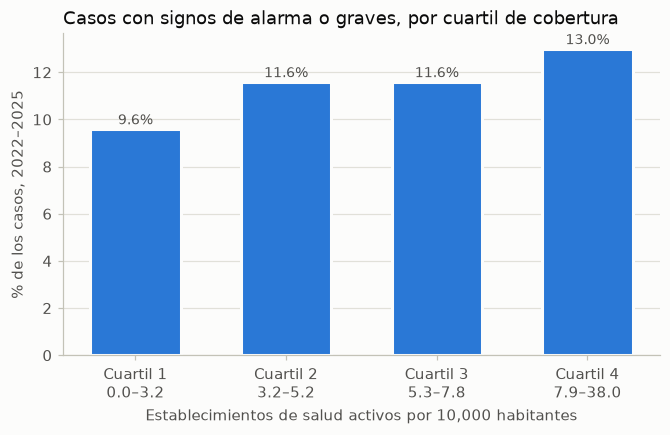

In [11]:
rows = by_quartile.collect()
fig, ax = plt.subplots(figsize=(7, 3.8))
x = range(len(rows))
ax.bar(x, [r.pct_warning_or_severe for r in rows], width=0.6, color=BLUE, edgecolor=SURFACE, linewidth=2)
for i, r in enumerate(rows):
    ax.annotate(f"{r.pct_warning_or_severe:.1f}%", (i, r.pct_warning_or_severe), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_xticks(list(x), [f"Cuartil {r.coverage_quartile}\n{r.min_per_10k}–{r.max_per_10k}" for r in rows])
ax.set_xlabel("Establecimientos de salud activos por 10,000 habitantes")
ax.set_title("Casos con signos de alarma o graves, por cuartil de cobertura")
ax.set_ylabel("% de los casos, 2022–2025")
save(fig, "q4_severity_coverage")
plt.show()

**Respuesta.** **No.** La proporción de casos con signos de alarma o graves es casi la misma con poca o mucha cobertura: la correlación es prácticamente nula (r = 0.07). La pequeña diferencia que existe va al revés de lo esperado: es algo mayor donde hay más establecimientos (13% frente a 10%), probablemente porque ahí se detectan mejor los signos de alarma.

## Q5 · ¿Los distritos en emergencia hídrica tuvieron mayor incidencia?

Los decretos de la SUNASS cubren 2017, 2023 y 2024; la población existe desde 2022, así que la comparación
usa 2023 y 2024.

**Tipos de join.**
- Población **LEFT JOIN** casos: se conservan todos los distritos, incluidos los que tienen cero casos.
  Comparar solo los distritos con casos ocultaría dónde *no* apareció el dengue.
- Ese resultado **LEFT JOIN** indicadores de emergencia: los distritos sin ningún decreto se quedan, con la
  etiqueta `none`.
- Las emergencias se agregan a una fila por distrito y año **antes** del join. Un distrito aparece una vez por
  decreto y por prórroga, así que unir las filas originales multiplicaría sus casos. Un **LEFT SEMI JOIN**
  ("quedarse con los casos cuyo distrito tuvo un decreto") lo evita por diseño, como muestran los conteos
  de abajo.

In [12]:
YEARS = [2023, 2024]
cases_2324 = cases.filter(F.col("year").isin(YEARS)).select("year", "ubigeo")
rain_rows = (emergencies.filter((F.col("emergency_type") == "rain") & F.col("year").isin(YEARS))
             .select("year", "ubigeo"))

print("Cases 2023-2024 in districts under a rain emergency")
print(f"  inner join with raw decree rows: {cases_2324.join(rain_rows, ['year', 'ubigeo'], 'inner').count():>9,}  (inflated)")
print(f"  left semi join                 : {cases_2324.join(rain_rows, ['year', 'ubigeo'], 'left_semi').count():>9,}")
print(f"  all cases 2023-2024            : {cases_2324.count():>9,}")

Cases 2023-2024 in districts under a rain emergency
  inner join with raw decree rows: 1,539,044  (inflated)
  left semi join                 :   352,213


  all cases 2023-2024            :   528,172


In [13]:
district_year = (population.filter(F.col("year").isin(YEARS))
                 .groupBy("year", "ubigeo", "department").agg(F.sum("population").alias("population"))
                 .join(cases_2324.groupBy("year", "ubigeo").agg(F.count("*").alias("cases")), ["year", "ubigeo"], "left")
                 .fillna(0, subset=["cases"]))

flags = (emergencies.filter(F.col("year").isin(YEARS))
         .groupBy("year", "ubigeo")
         .agg(*[F.max((F.col("emergency_type") == kind).cast("int")).alias(kind) for kind in ("rain", "drought", "other")],
              F.avg("water_hours_per_day").alias("water_hours_per_day")))

emergency_districts = (district_year.join(flags, ["year", "ubigeo"], "left")
                       .withColumn("emergency", F.when((F.col("rain") == 1) & (F.col("drought") == 1), "rain and drought")
                                                 .when(F.col("rain") == 1, "rain")
                                                 .when(F.col("drought") == 1, "drought")
                                                 .when(F.col("other") == 1, "other")
                                                 .otherwise("none")))

# Departments with real transmission that year (1,000+ cases), to compare like with like
dengue_departments = (district_year.groupBy("year", "department").agg(F.sum("cases").alias("cases"))
                      .filter(F.col("cases") >= 1000).select("year", "department"))


def incidence_by(df, *keys):
    return (df.groupBy(*keys)
            .agg(F.count("*").alias("districts"),
                 F.sum("cases").alias("cases"),
                 F.round(F.sum("cases") / F.sum("population") * 100_000, 1).alias("incidence_100k"),
                 F.round(F.avg((F.col("cases") > 0).cast("int")) * 100, 1).alias("pct_districts_with_cases"))
            .orderBy(*keys))


print("All districts")
incidence_by(emergency_districts, "year", "emergency").show()
print("Only departments with 1,000+ cases that year")
in_dengue_departments = emergency_districts.join(dengue_departments, ["year", "department"], "left_semi")
by_emergency = incidence_by(in_dengue_departments, "year", "emergency")
by_emergency.show()

All districts


+----+----------------+---------+------+--------------+------------------------+
|year|       emergency|districts| cases|incidence_100k|pct_districts_with_cases|
+----+----------------+---------+------+--------------+------------------------+
|2023|         drought|      479|  4968|          80.2|                     6.1|
|2023|            none|      143| 20905|         447.8|                    89.5|
|2023|           other|        1|    46|          49.0|                   100.0|
|2023|            rain|      742|223188|        1037.6|                    48.4|
|2023|rain and drought|      526|  7534|         256.0|                     4.4|
|2024|            none|     1021|150040|         660.0|                    25.0|
|2024|            rain|      870|121491|         940.4|                    35.2|
+----+----------------+---------+------+--------------+------------------------+

Only departments with 1,000+ cases that year


+----+----------------+---------+------+--------------+------------------------+
|year|       emergency|districts| cases|incidence_100k|pct_districts_with_cases|
+----+----------------+---------+------+--------------+------------------------+
|2023|         drought|      241|  4853|         168.9|                    11.2|
|2023|            none|      139| 20753|         446.2|                    90.6|
|2023|           other|        1|    46|          49.0|                   100.0|
|2023|            rain|      716|223188|        1040.0|                    50.1|
|2023|rain and drought|      215|  6839|         578.0|                     6.0|
|2024|            none|      642|148283|         820.6|                    33.0|
|2024|            rain|      527|119950|        1168.6|                    52.4|
+----+----------------+---------+------+--------------+------------------------+



In [14]:
water = (in_dengue_departments.filter(F.col("water_hours_per_day").isNotNull())
         .withColumn("water_supply", F.when(F.col("water_hours_per_day") < 12, "1. under 12 h/day")
                                      .when(F.col("water_hours_per_day") < 24, "2. 12-23 h/day")
                                      .otherwise("3. 24 h/day")))
print("Districts under a decree, by hours of water supply per day (departments with 1,000+ cases)")
incidence_by(water, "water_supply").show(truncate=False)

Districts under a decree, by hours of water supply per day (departments with 1,000+ cases)


+-----------------+---------+------+--------------+------------------------+
|water_supply     |districts|cases |incidence_100k|pct_districts_with_cases|
+-----------------+---------+------+--------------+------------------------+
|1. under 12 h/day|511      |215126|1773.3        |67.7                    |
|2. 12-23 h/day   |1173     |139551|588.9         |27.5                    |
|3. 24 h/day      |10       |3     |22.1          |20.0                    |
+-----------------+---------+------+--------------+------------------------+



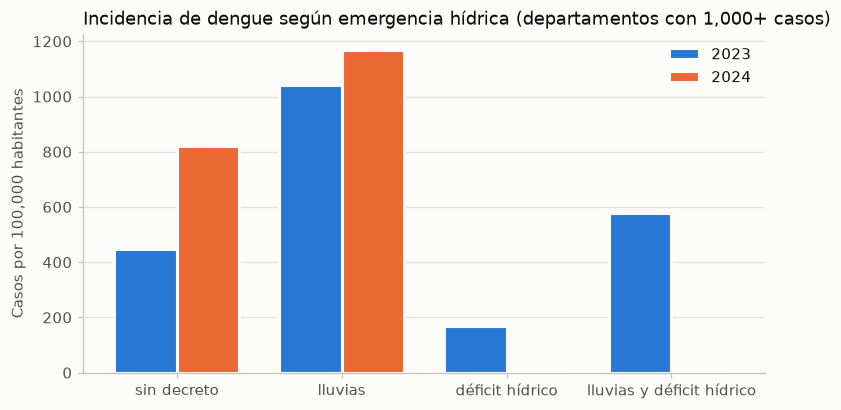

In [15]:
grid = {(r.year, r.emergency): r.incidence_100k for r in by_emergency.collect()}
groups = [g for g in ("none", "rain", "drought", "rain and drought") if any(k[1] == g for k in grid)]
width = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
for offset, year, color in ((-width / 2, 2023, BLUE), (width / 2, 2024, ORANGE)):
    ax.bar([i + offset for i in range(len(groups))], [grid.get((year, g), 0) for g in groups], width=width,
           color=color, label=str(year), edgecolor=SURFACE, linewidth=2)
labels = {"none": "sin decreto", "rain": "lluvias", "drought": "déficit hídrico",
          "rain and drought": "lluvias y déficit hídrico"}
ax.set_xticks(range(len(groups)), [labels[g] for g in groups])
ax.set_title("Incidencia de dengue según emergencia hídrica (departamentos con 1,000+ casos)")
ax.set_ylabel("Casos por 100,000 habitantes")
ax.legend(loc="upper right")
save(fig, "q5_water_emergencies")
plt.show()

**Respuesta.** **Sí, en las emergencias por lluvias.** En los departamentos con transmisión de dengue, los distritos en emergencia por lluvias tuvieron más incidencia que los distritos sin decreto: 2.3 veces más en 2023 y 1.4 veces más en 2024. Las emergencias por déficit hídrico no muestran ese aumento, porque se declararon sobre todo en departamentos andinos, donde casi no hay dengue.

**Continuidad del agua:** sí influye. Los distritos con menos de 12 horas de agua al día tuvieron 3 veces más incidencia que los que tienen entre 12 y 23 horas.

## Q6 · ¿Cuántas semanas después de la lluvia aumentan los casos? Costa vs selva

Cada estación del SENAMHI se empareja con los casos de dengue de **su provincia**. La lluvia diaria se suma
por semana epidemiológica (una semana necesita al menos 5 días medidos). Para cada desfase (*lag*) de 0 a 12
semanas se calcula, por estación, la correlación entre la lluvia de la semana *t* y los casos de la semana
*t + desfase* (los casos se transforman con logaritmo porque los brotes abarcan varios órdenes de magnitud).

**Tipos de join.**
- Estaciones **CROSS JOIN** un calendario semanal: cada estación recibe todas las semanas, así una semana sin
  datos queda como un hueco en lugar de desplazar la serie de tiempo (`lead` cuenta filas, no fechas).
- Calendario **LEFT JOIN** lluvia semanal y casos semanales: las semanas sin casos son ceros reales y se
  mantienen.

El calendario semanal se construye con `spark.range`; `lead` sobre una ventana particionada por estación
construye las 13 columnas desfasadas en una sola pasada, y `unpivot` las convierte en filas.

In [16]:
COAST = ["105100", "104079", "103038"]  # Miraflores (Piura), Mallares (Sullana), Puerto Pizarro (Tumbes)
LAGS = list(range(13))

FIRST_WEEK, LAST_WEEK = date(2022, 1, 2), date(2025, 12, 28)  # Sundays starting epi weeks 2022-01 and 2025-52
calendar = (spark.range((LAST_WEEK - FIRST_WEEK).days // 7 + 1)
            .select(F.date_add(F.lit(FIRST_WEEK), (F.col("id") * 7).cast("int")).alias("week_start")))
stations = (weather.select("station_code", "station_name", "ubigeo").distinct()
            .withColumn("province_code", F.substring("ubigeo", 1, 4))
            .withColumn("region", F.when(F.col("station_code").isin(COAST), "coast").otherwise("jungle")))
weekly_rain = (weather
               .withColumn("week_start", F.date_sub("date", F.dayofweek("date") - 1))
               .groupBy("station_code", "week_start")
               .agg(F.sum("precip_mm").alias("rain_mm"), F.count("precip_mm").alias("days_measured")))
weekly_cases = (cases.withColumn("province_code", F.substring("ubigeo", 1, 4))
                .groupBy("province_code", "week_start").agg(F.count("*").alias("cases")))

station_weeks = (stations.crossJoin(calendar)
                 .join(weekly_rain, ["station_code", "week_start"], "left")
                 .join(weekly_cases, ["province_code", "week_start"], "left")
                 .withColumn("rain_mm", F.when(F.col("days_measured") >= 5, F.col("rain_mm")))
                 .fillna(0, subset=["cases"]))

(station_weeks.groupBy("region", "station_name", "province_code")
 .agg(F.count("*").alias("weeks"), F.count("rain_mm").alias("weeks_with_rain_data"),
      F.round(F.sum("rain_mm") / 4).alias("yearly_rain_mm"), F.sum("cases").alias("province_cases"),
      F.max("cases").alias("peak_week_cases"))
 .orderBy("region", F.desc("province_cases")).show(truncate=False))

+------+----------------+-------------+-----+--------------------+--------------+--------------+---------------+
|region|station_name    |province_code|weeks|weeks_with_rain_data|yearly_rain_mm|province_cases|peak_week_cases|
+------+----------------+-------------+-----+--------------------+--------------+--------------+---------------+
|coast |MIRAFLORES      |2001         |209  |186                 |195.0         |59806         |4720           |
|coast |MALLARES        |2006         |209  |184                 |174.0         |20244         |1892           |
|coast |PUERTO PIZARRO  |2401         |209  |187                 |467.0         |16436         |701            |
|jungle|PUCALLPA        |2501         |209  |204                 |1593.0        |11716         |541            |
|jungle|SHANUSI         |1602         |209  |208                 |2570.0        |11267         |377            |
|jungle|TARAPOTO        |2209         |209  |206                 |1392.0        |11163         |

In [17]:
by_week = Window.partitionBy("station_code").orderBy("week_start")
ids = ["station_code", "station_name", "region"]

lag_corr = (station_weeks
            .select(*ids, "rain_mm", *[(F.log1p("cases") if lag == 0 else F.lead(F.log1p("cases"), lag).over(by_week)).alias(str(lag))
                      for lag in LAGS])
            .groupBy(*ids)
            .agg(*[F.corr("rain_mm", str(lag)).alias(str(lag)) for lag in LAGS])
            .unpivot(ids, [str(lag) for lag in LAGS], "lag_weeks", "r")
            .withColumn("lag_weeks", F.col("lag_weeks").cast("int"))
            .cache())

best_lag = (lag_corr.withColumn("rank", F.row_number().over(Window.partitionBy("station_code").orderBy(F.desc("r"))))
            .filter(F.col("rank") == 1)
            .select("region", "station_name", "lag_weeks", F.round("r", 2).alias("r"))
            .orderBy("region", F.desc("r")))
best_lag.show(truncate=False)

print("Average correlation by region and lag")
(lag_corr.groupBy("region").pivot("lag_weeks", LAGS).agg(F.round(F.avg("r"), 2)).orderBy("region").show())

+------+----------------+---------+----+
|region|station_name    |lag_weeks|r   |
+------+----------------+---------+----+
|coast |MALLARES        |7        |0.44|
|coast |MIRAFLORES      |8        |0.38|
|coast |PUERTO PIZARRO  |10       |0.26|
|jungle|AMAZONAS        |0        |0.26|
|jungle|MOYOBAMBA       |5        |0.26|
|jungle|PUERTO MALDONADO|5        |0.22|
|jungle|TARAPOTO        |7        |0.21|
|jungle|PUCALLPA        |5        |0.16|
|jungle|SHANUSI         |1        |0.1 |
+------+----------------+---------+----+

Average correlation by region and lag


+------+----+----+----+----+----+----+----+----+----+----+----+----+----+
|region|   0|   1|   2|   3|   4|   5|   6|   7|   8|   9|  10|  11|  12|
+------+----+----+----+----+----+----+----+----+----+----+----+----+----+
| coast|0.19|0.21|0.24|0.27|0.29|0.31|0.33|0.35|0.35|0.35|0.35|0.33|0.31|
|jungle|0.17|0.17|0.17|0.15|0.16|0.17|0.15|0.14|0.12| 0.1|0.08|0.07|0.04|
+------+----+----+----+----+----+----+----+----+----+----+----+----+----+



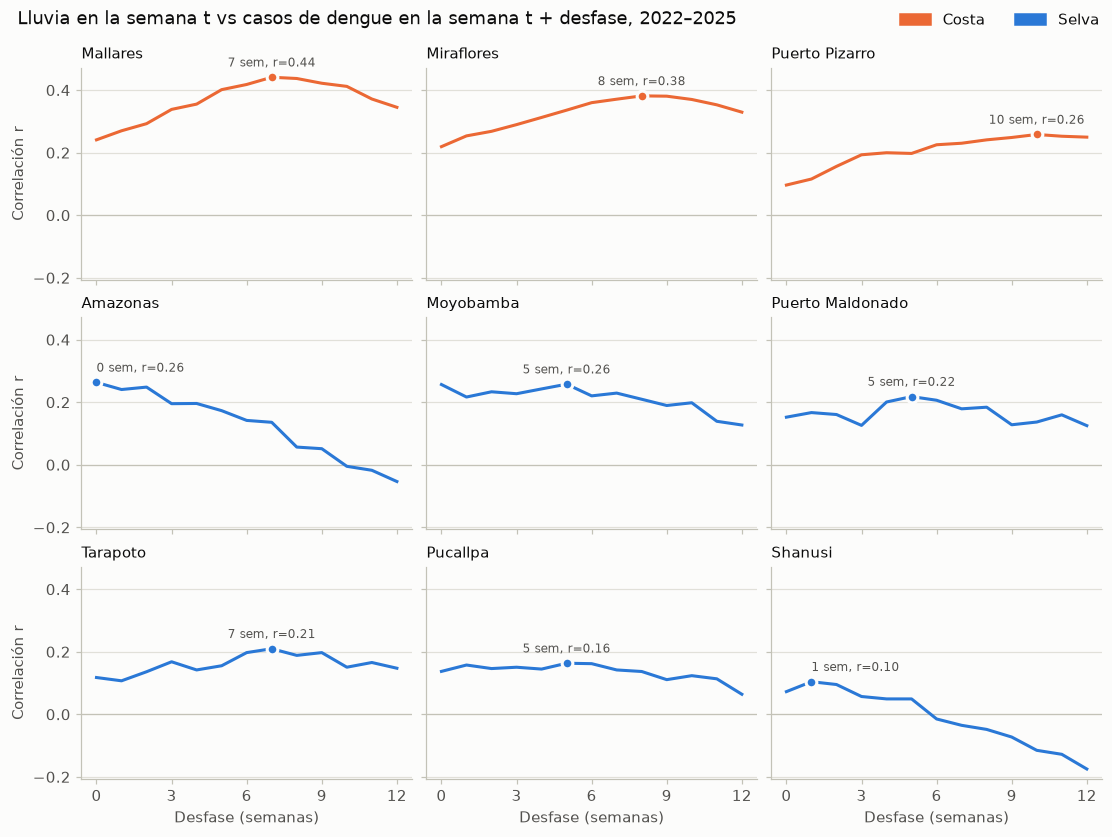

In [18]:
curves = {}
for r in lag_corr.orderBy("lag_weeks").collect():
    curves.setdefault((r.region, r.station_name), []).append(r.r)
order = sorted(curves, key=lambda k: (k[0], -max(curves[k])))

fig, axes = plt.subplots(3, 3, figsize=(10, 7.5), sharex=True, sharey=True, layout="constrained")
for ax, key in zip(axes.flat, order):
    region, name = key
    color = ORANGE if region == "coast" else BLUE
    values = curves[key]
    best = max(range(len(values)), key=lambda i: values[i])
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.plot(LAGS, values, color=color, linewidth=2)
    ax.plot(best, values[best], "o", color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{best} sem, r={values[best]:.2f}", (best, values[best]), xytext=(0, 7), textcoords="offset points",
                ha="left" if best <= 1 else "right" if best >= 11 else "center", fontsize=8, color=INK_2)
    ax.set_title(name.title(), fontsize=10)
    ax.set_xticks([0, 3, 6, 9, 12])
for ax in axes[-1]:
    ax.set_xlabel("Desfase (semanas)")
for ax in axes[:, 0]:
    ax.set_ylabel("Correlación r")
fig.legend(handles=[Patch(color=ORANGE, label="Costa"), Patch(color=BLUE, label="Selva")],
           loc="outside upper right", ncol=2)
fig.suptitle("Lluvia en la semana t vs casos de dengue en la semana t + desfase, 2022–2025", x=0.01, ha="left", fontsize=12)
save(fig, "q6_rain_lag_by_station")
plt.show()

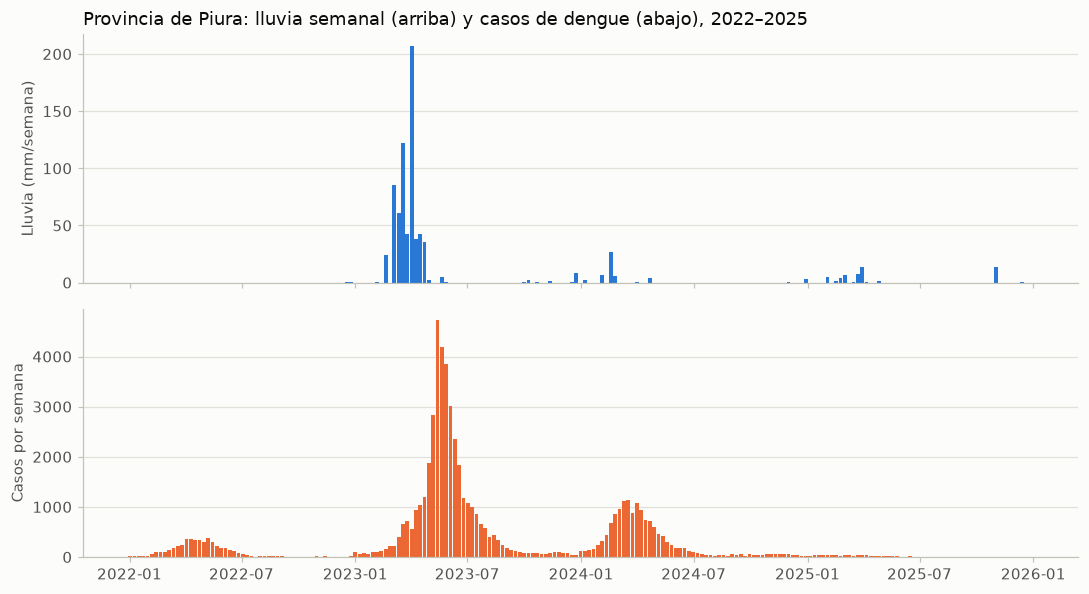

In [19]:
# Piura province: weekly rain (Miraflores station) and weekly cases, in two panels sharing the time axis
piura = (station_weeks.filter(F.col("station_code") == "105100")
         .select("week_start", "rain_mm", "cases").orderBy("week_start").collect())
weeks = [r.week_start for r in piura]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
top.bar(weeks, [r.rain_mm or 0 for r in piura], width=6, color=BLUE)
top.set_title("Provincia de Piura: lluvia semanal (arriba) y casos de dengue (abajo), 2022–2025")
top.set_ylabel("Lluvia (mm/semana)")
bottom.bar(weeks, [r.cases for r in piura], width=6, color=ORANGE)
bottom.set_ylabel("Casos por semana")
fig.tight_layout()
save(fig, "q6_piura_weekly")
plt.show()

**Respuesta.**

- **Costa:** los casos aumentan **entre 7 y 10 semanas después de la lluvia** (unos dos meses). El gráfico de Piura lo muestra: tras las lluvias de febrero a abril de 2023, los casos llegaron a su pico en mayo.
- **Selva:** **no hay un desfase claro**; la relación entre lluvia y casos es débil. Allí llueve todo el año, así que la lluvia no marca cuándo empieza un brote.

## Summary

| # | Question | Answer |
|---|---|---|
| 1 | Evolution and epidemic years | About 49 times more cases in 2024 than in 2000. Six epidemic years (2001, 2008, 2011, 2017, 2023, 2024): coastal ones led by Piura, Amazon ones led by Loreto. 2023–2024 hold half of all cases since 2000. |
| 2 | Highest incidence | La Huaca (Piura): 4,228 cases per 100,000 per year. 10 of the top 15 districts are coastal. |
| 3 | Age and sex | Women +18% over men, driven by adult women. Highest rate in adolescents aged 12–17. |
| 4 | Severity vs facilities | No sign that fewer facilities mean more severe cases (r = 0.07); the slight opposite trend points to under-detection. |
| 5 | Water emergencies | Rain emergencies: 1.4–2.3 times higher incidence. Under 12 h of water a day: 3 times higher than 12–23 h. |
| 6 | Rain → cases | Coast: cases follow rain by 7–10 weeks. Jungle: no consistent lag. |

**Spark operations used in this notebook**

- Transformations: `select`, `filter`, `withColumn`, `when`, `fillna`, `pivot`, `unpivot`.
- Joins: `left`, `inner`, `left_semi`, `left_anti`, `cross`, each one justified where it is used.
- Aggregations: `groupBy` + `agg` with `count`, `sum`, `avg`, `min`, `max`, `corr`, and `orderBy`.
- Window functions: `lag`, `lead`, a moving average with `rowsBetween`, `row_number`, `dense_rank`, `ntile`.

In [20]:
spark.stop()